**German Bank Mortage Defaults**

In [1]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
import umap.umap_ as umap
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score
from sklearn.svm import SVC
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from xgboost import XGBClassifier

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.utils.multiclass import unique_labels

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# load dataset
df = pd.read_excel('german_bank.xlsx')

print(df.head())
print(list(df.columns))
print(df.dtypes)

  checking_balance  months_loan_duration credit_history               purpose  \
0           < 0 DM                     6       critical  furniture/appliances   
1       1 - 200 DM                    48           good  furniture/appliances   
2          unknown                    12       critical             education   
3           < 0 DM                    42           good  furniture/appliances   
4           < 0 DM                    24           poor                   car   

   amount savings_balance employment_duration  percent_of_income  \
0    1169         unknown           > 7 years                  4   
1    5951        < 100 DM         1 - 4 years                  2   
2    2096        < 100 DM         4 - 7 years                  2   
3    7882        < 100 DM         4 - 7 years                  2   
4    4870        < 100 DM         1 - 4 years                  3   

   years_at_residence  age other_credit housing  existing_loans_count  \
0                   4   67     

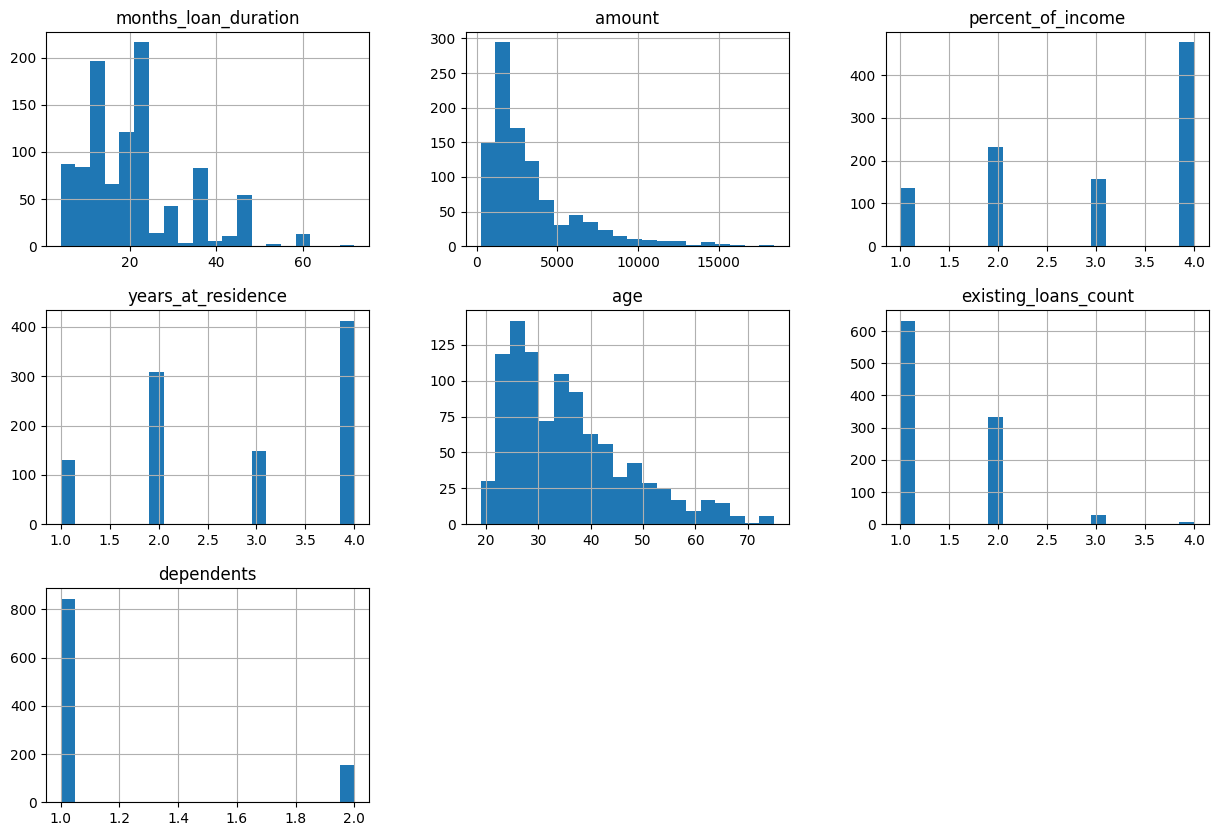

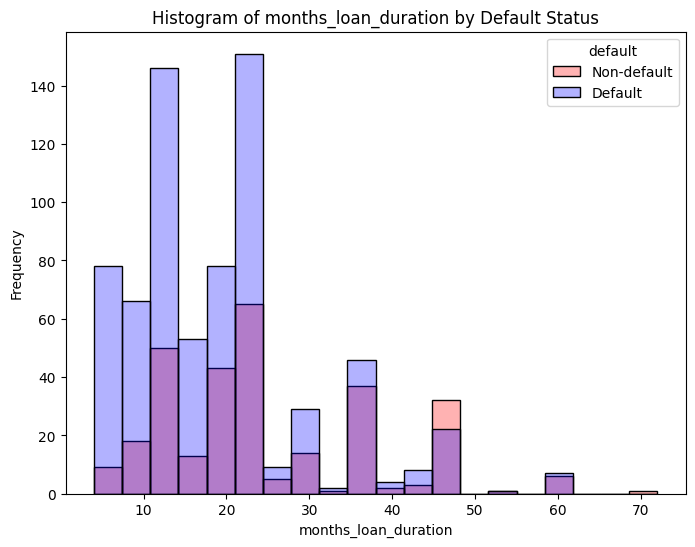

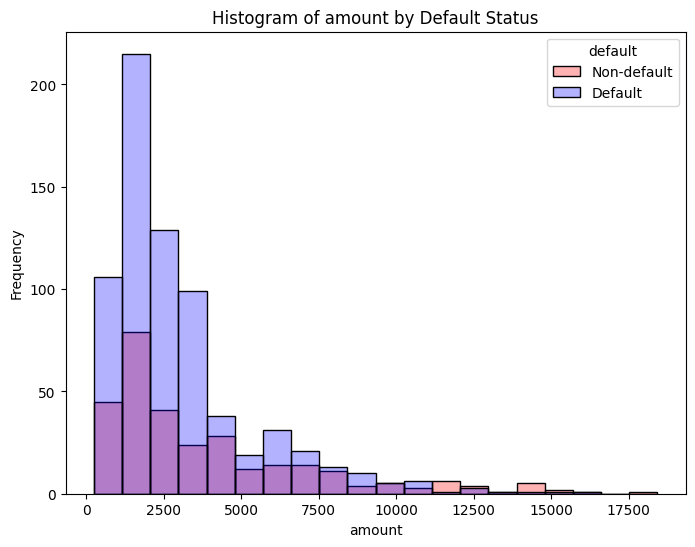

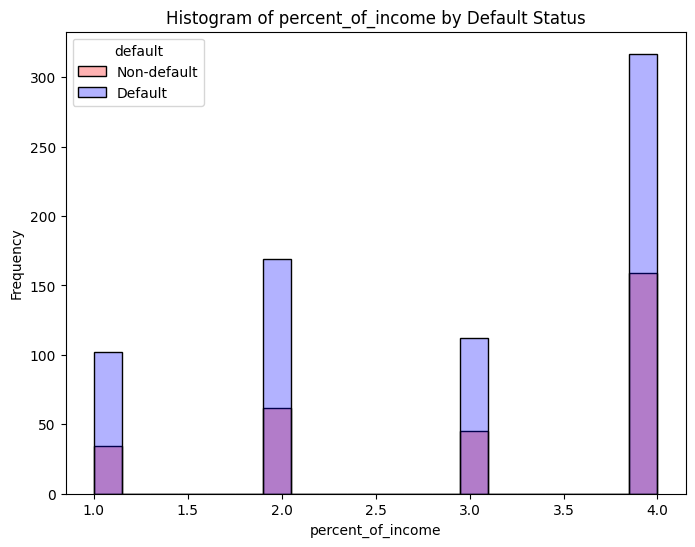

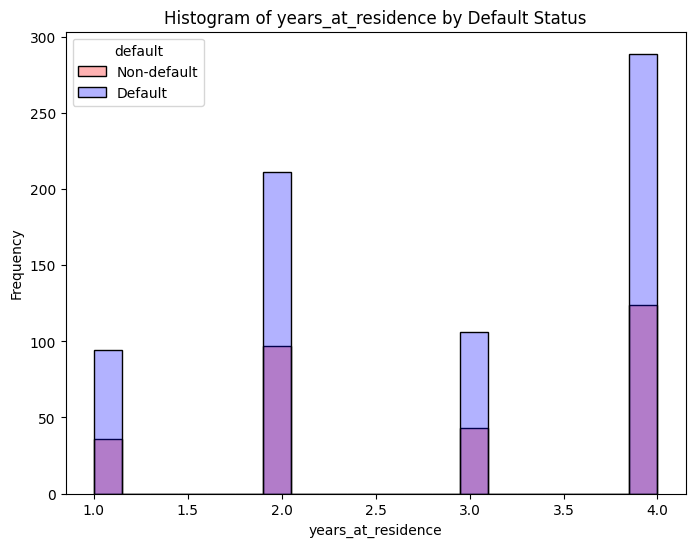

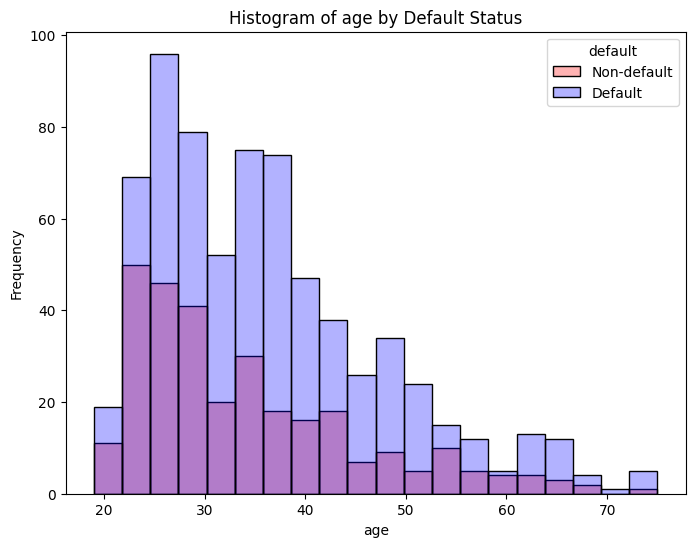

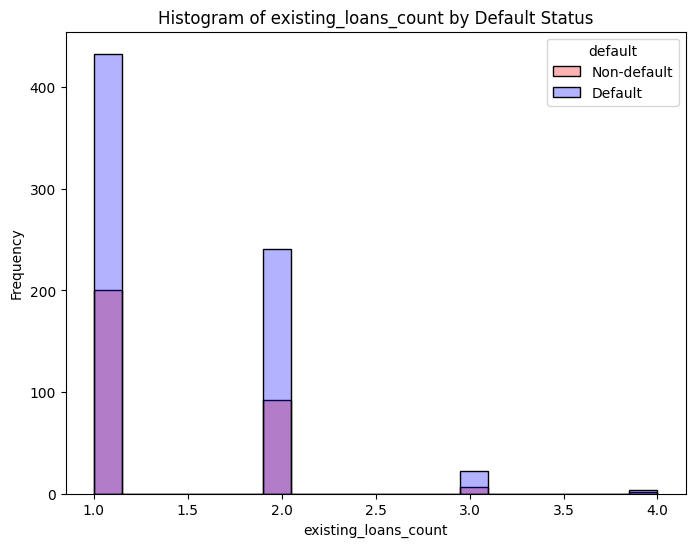

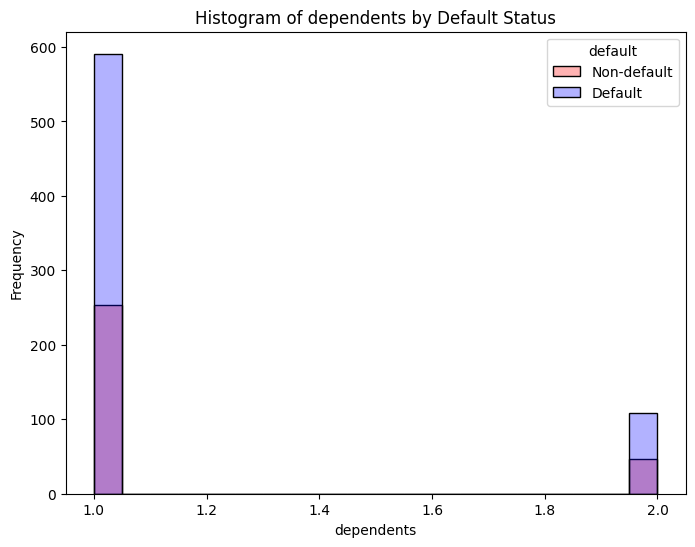

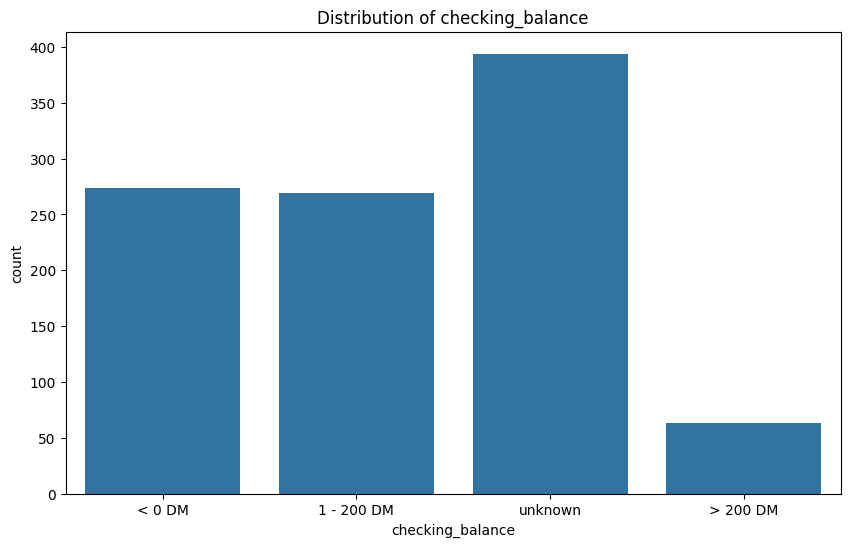

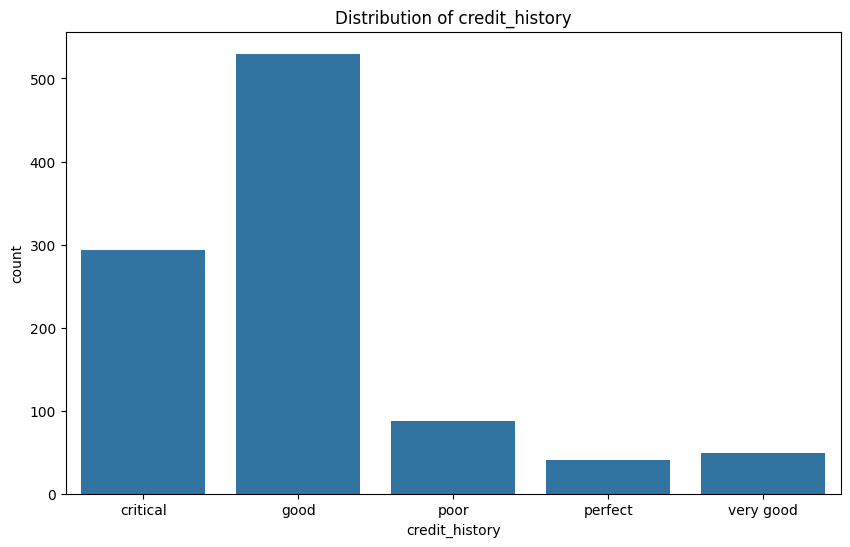

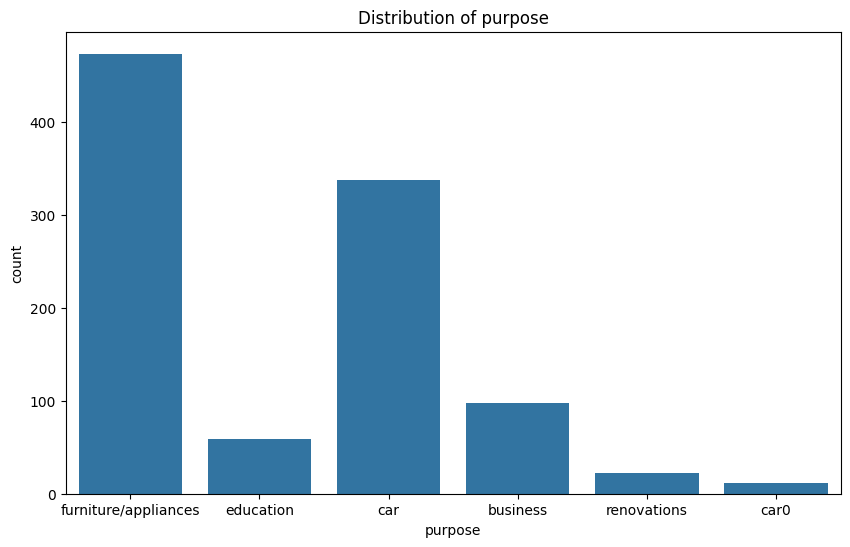

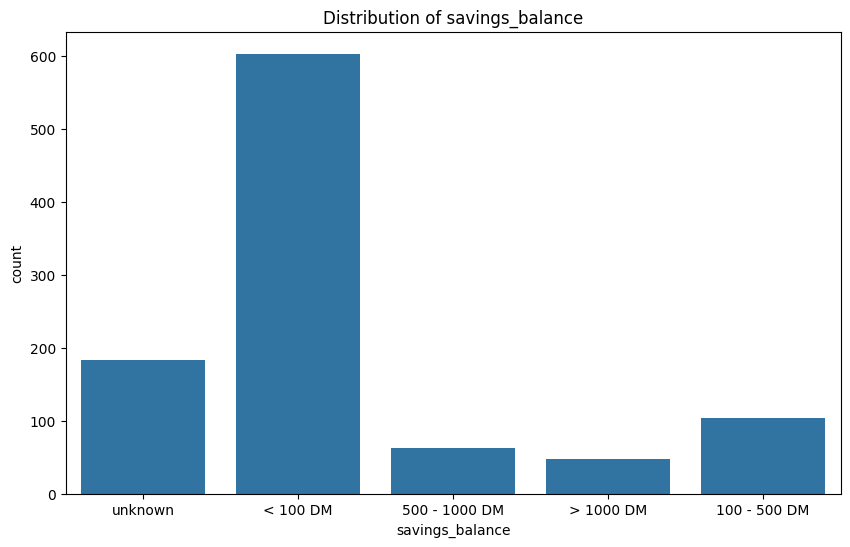

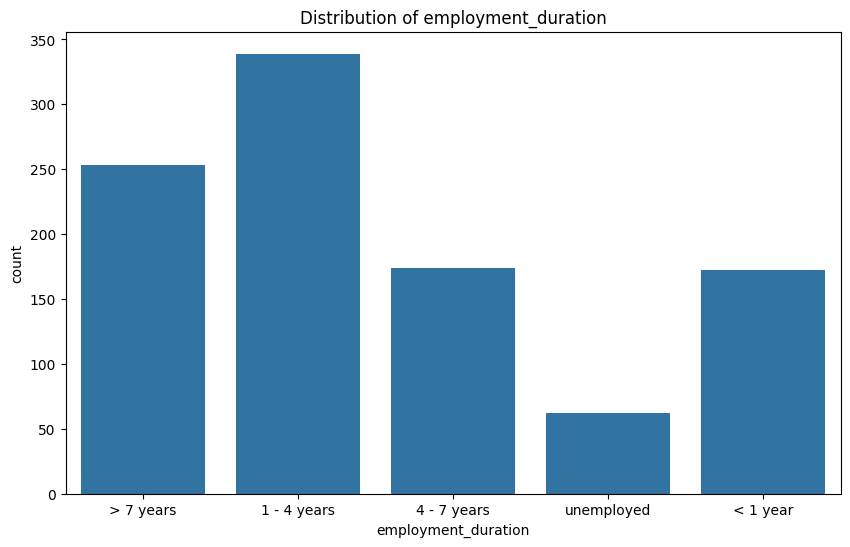

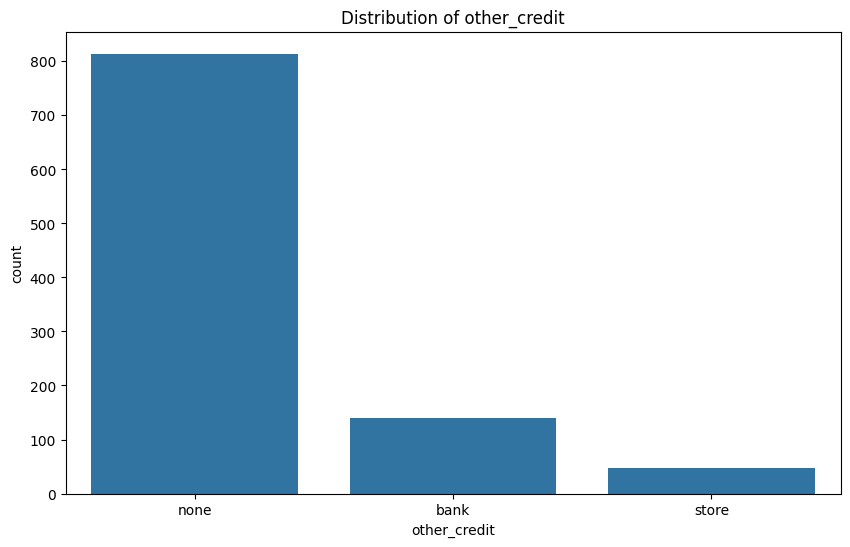

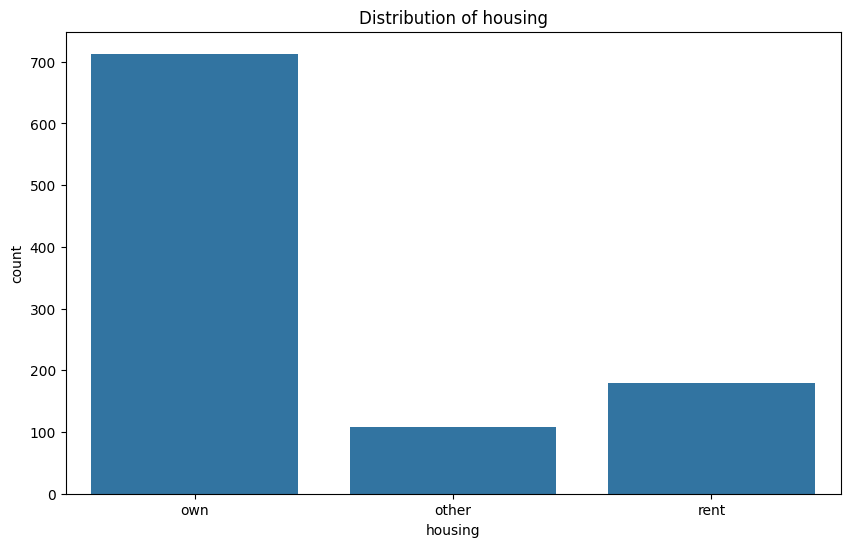

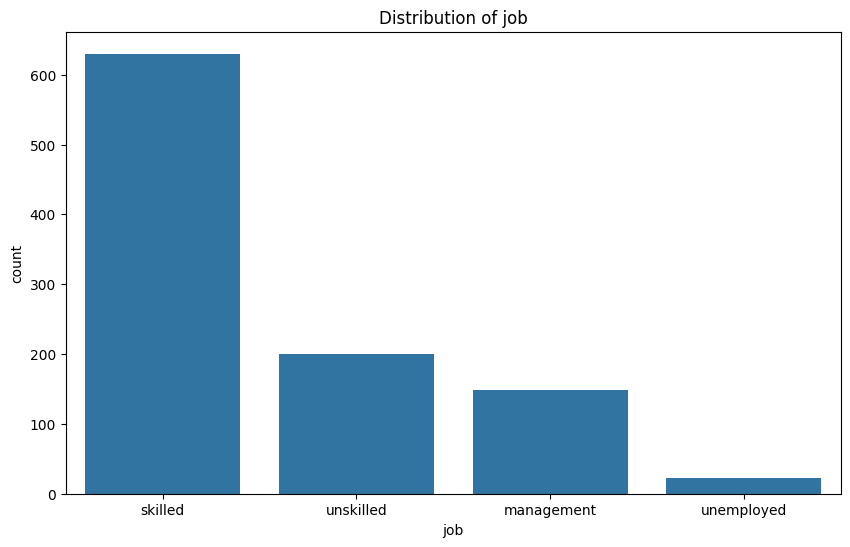

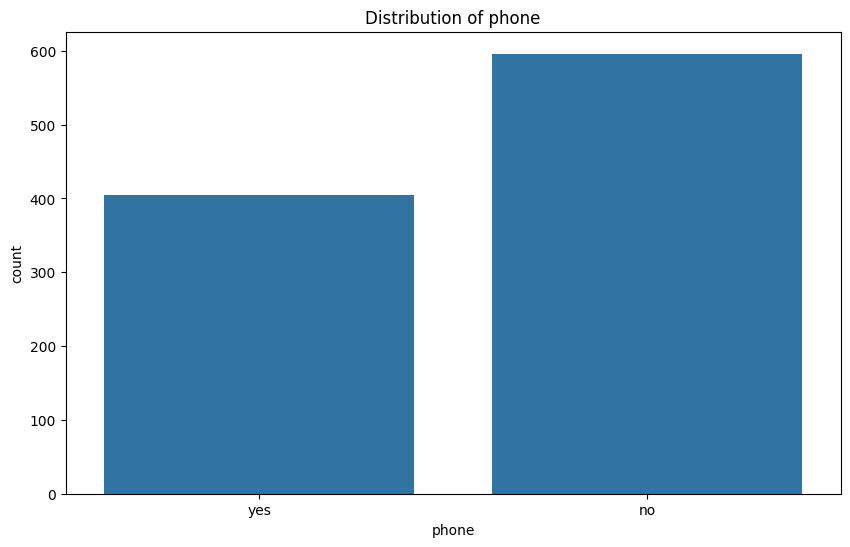

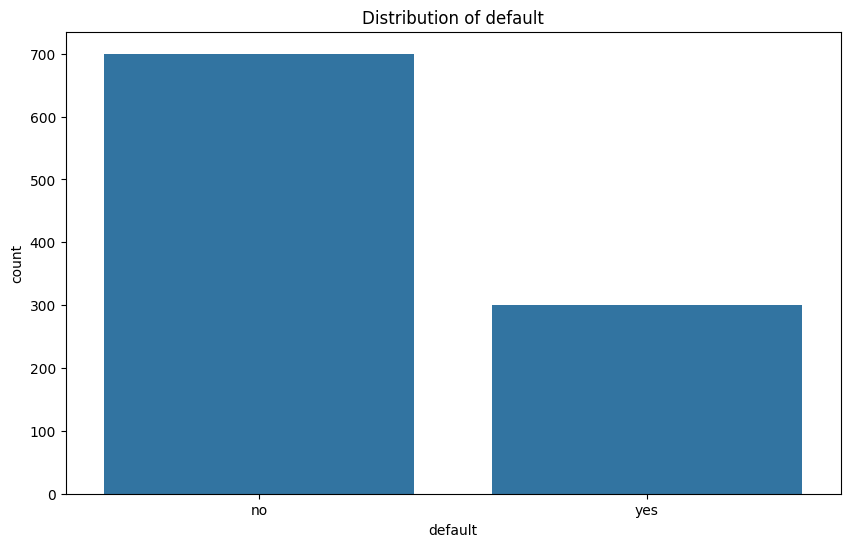

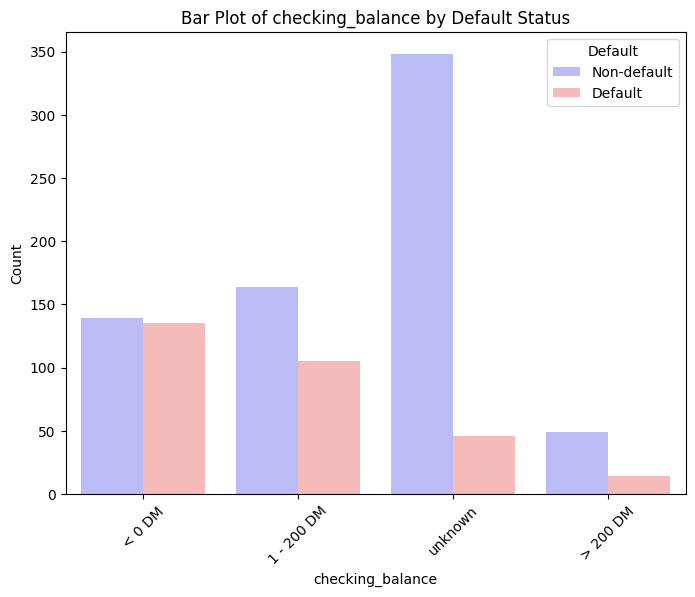

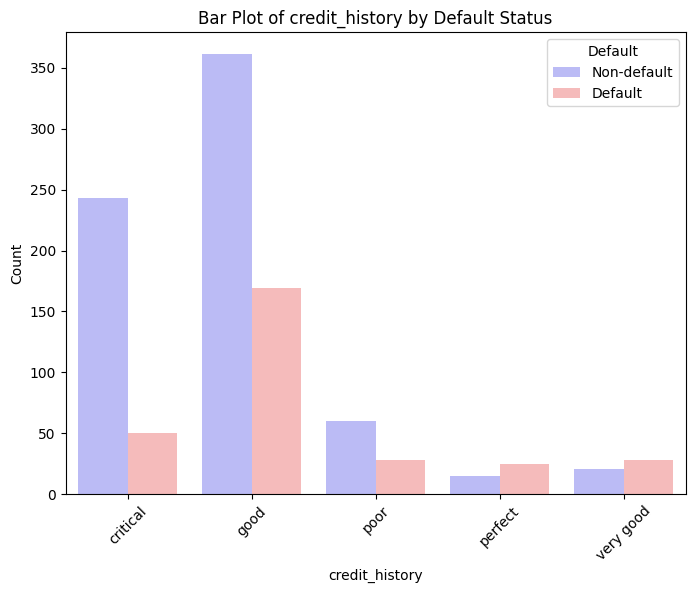

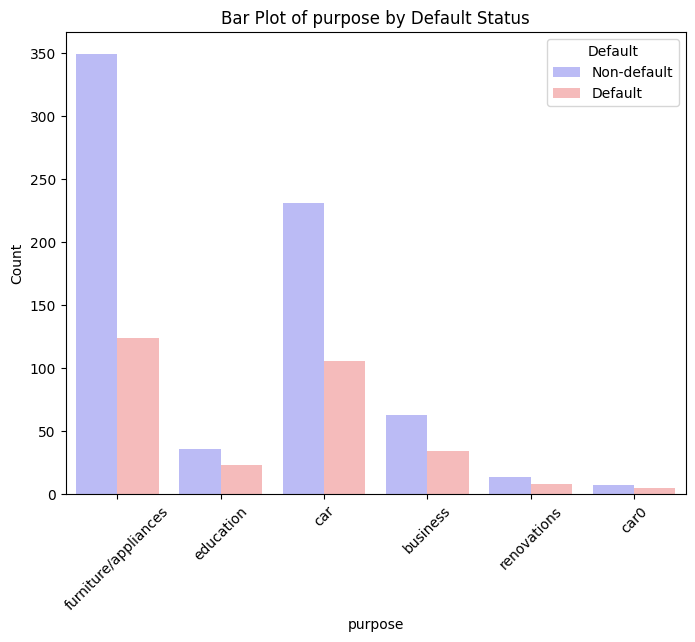

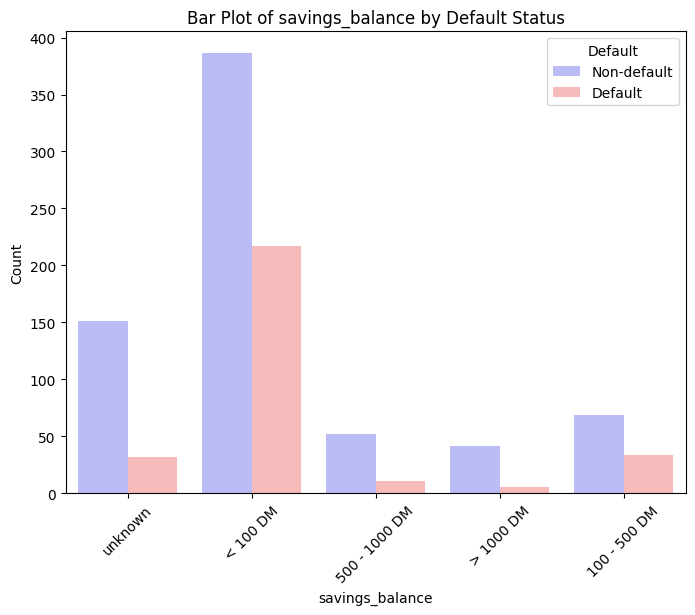

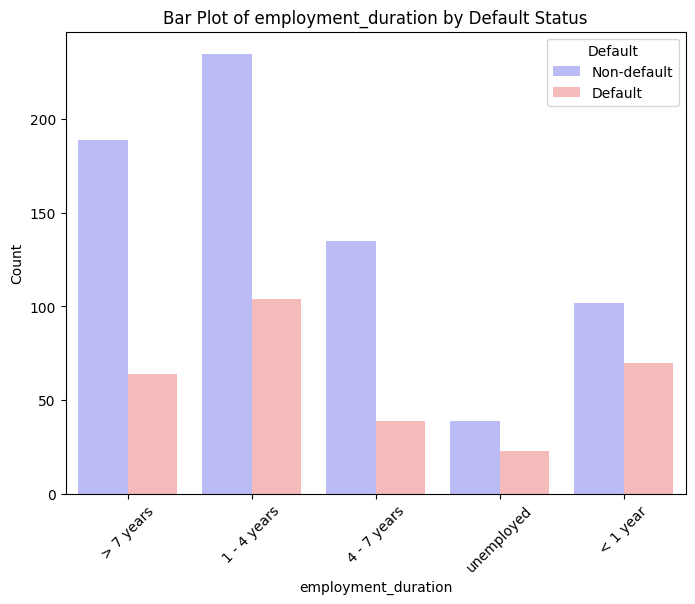

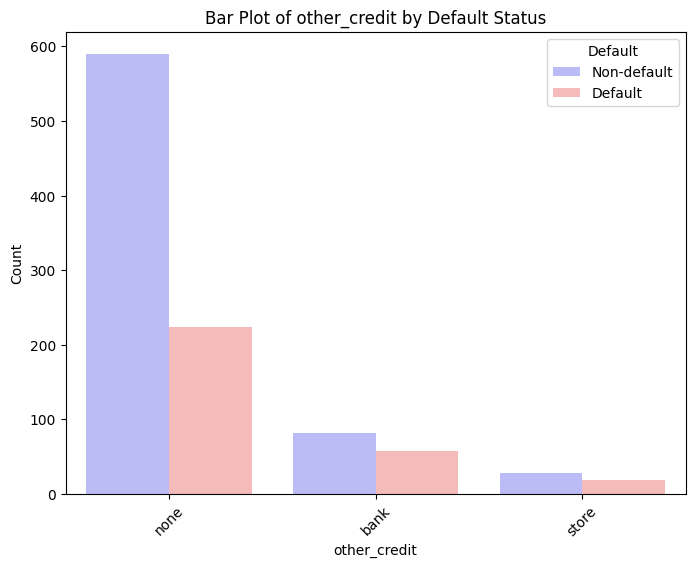

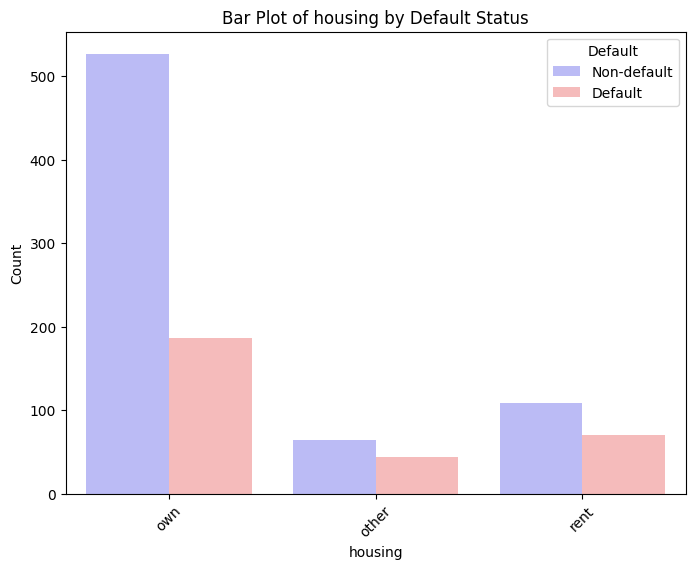

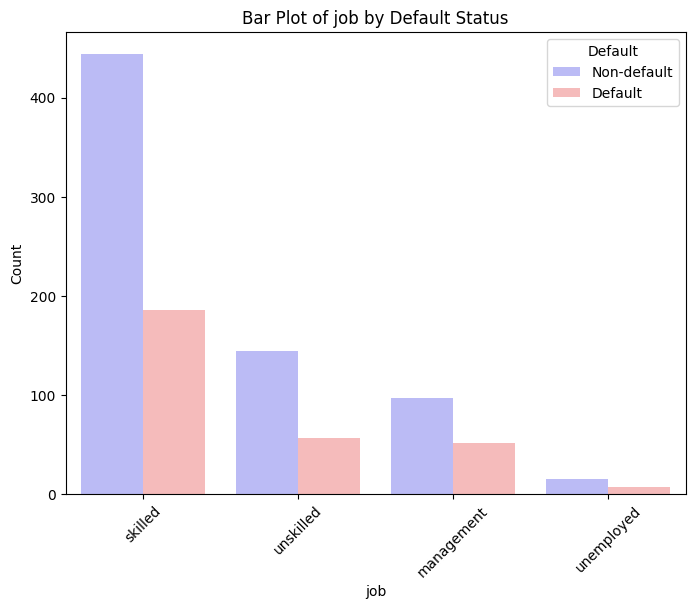

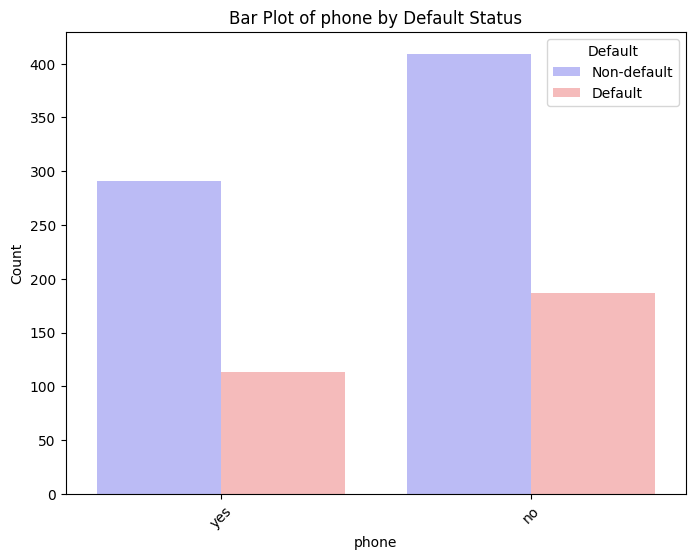

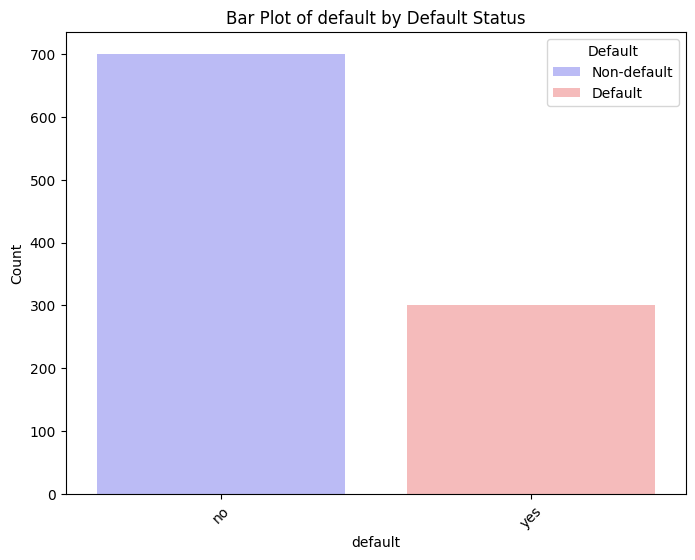

In [5]:
# Plot histograms of all numerical features
df.hist(bins=20, figsize=(15, 10))
plt.show()

# Plot histograms for each numeric column
for col in df.select_dtypes('int64').columns:
    plt.figure(figsize=(8, 6))
    
    # Use seaborn for easier handling of group-wise colors
    sns.histplot(data=df, x=col, hue='default', kde=False, 
                    palette={'yes': 'red', 'no': 'blue'}, bins=20, alpha=0.3)
    
    plt.title(f"Histogram of {col} by Default Status")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.legend(title='default', labels=['Non-default', 'Default'])
    plt.show()
    
# Bar plot for categorical features
for col in df.select_dtypes(include='object').columns:
    plt.figure(figsize=(10, 6))
    sns.countplot(x=col, data=df)
    plt.title(f'Distribution of {col}')
    plt.show()

# Bar plot for categorical features with classes
for col in df.select_dtypes(include='object').columns:
    plt.figure(figsize=(8, 6))
    
    # Count plot for the categorical feature grouped by target
    sns.countplot(data=df, x=col, hue='default', palette={'yes': 'red', 'no': 'blue'}, alpha=0.3)
    
    plt.title(f"Bar Plot of {col} by Default Status")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.legend(title='Default', labels=['Non-default', 'Default'])
    plt.xticks(rotation=45)  # Rotate x-axis labels if necessary
    plt.show()

In [3]:
# Load dataset
df = pd.read_excel(r"C:\Users\nswat\Documents\University of Delaware\Fall 2024\STAT617\project\germanbank_encoded.xlsx")
# Convert columns with 0 and 1 to boolean
df = df.apply(lambda x: x.astype(bool) if set(x.unique()) == {0, 1} else x)

print(df.head())
print(list(df.columns))
print(df.dtypes)

# Separate features (X) and target variable (y)
X = df.drop(columns=['default'])
y = df['default']

# Identify numeric features
numeric_features = X.select_dtypes(include=['int64']).columns
print(numeric_features)

# Standardize only numeric features
scaler = StandardScaler()
X_std = X.copy()
X_std[numeric_features] = scaler.fit_transform(X[numeric_features])

# Split the data into training and testing sets (80-20 split)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

   months_loan_duration  amount  percent_of_income  years_at_residence  age  \
0                     6    1169                  4                   4   67   
1                    48    5951                  2                   2   22   
2                    12    2096                  2                   3   49   
3                    42    7882                  2                   4   45   
4                    24    4870                  3                   4   53   

   existing_loans_count  dependents  default  credit_history  \
0                     2           1    False               0   
1                     1           1     True               2   
2                     1           2    False               0   
3                     1           2    False               2   
4                     2           2     True               1   

   employment_duration  ...  other_credit_store  housing_other  housing_own  \
0                    4  ...               False          Fals

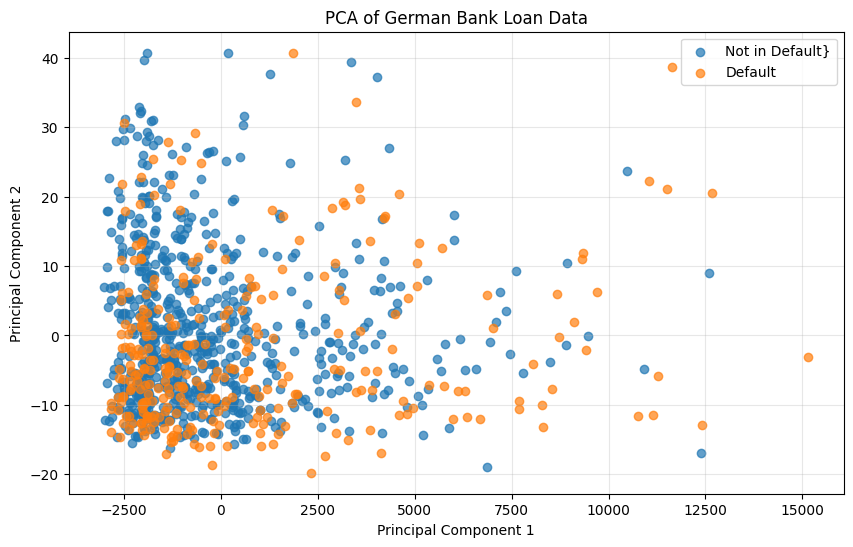

In [7]:
# Perform PCA to reduce to 2 components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Plot the PCA-transformed data
plt.figure(figsize=(10, 6))
for label in np.unique(y):
    plt.scatter(
        X_pca[y == label, 0],
        X_pca[y == label, 1],
        label="Default" if label else "Not in Default}",
        alpha=0.7
    )

# Add plot details
plt.title('PCA of German Bank Loan Data')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


Use Linear Discriminant Analysis to predict default in borrowers.


Running LDA...


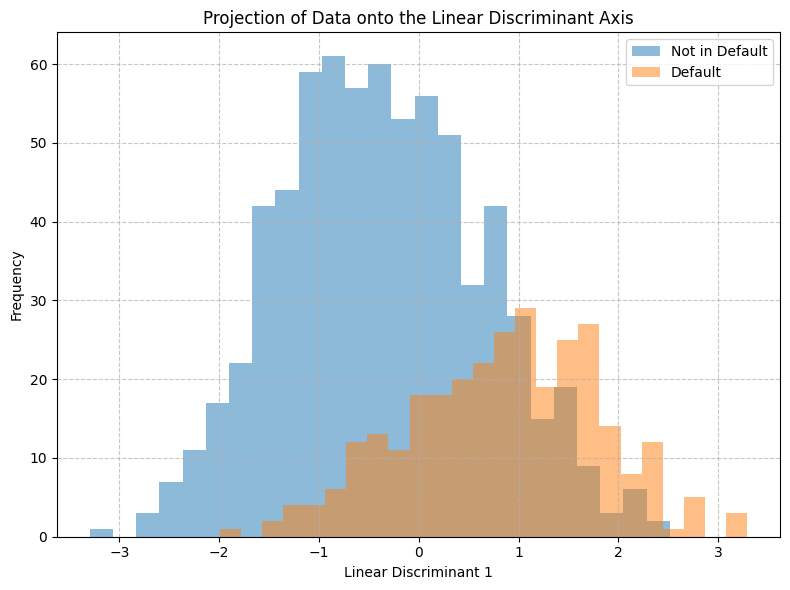

LDA 5-fold CV accuracy: 0.739
LDA Classification Report:
               precision    recall  f1-score   support

       False       0.80      0.90      0.85       700
        True       0.67      0.48      0.56       300

    accuracy                           0.77      1000
   macro avg       0.74      0.69      0.70      1000
weighted avg       0.76      0.77      0.76      1000



In [36]:
# --- LDA ---
print("\nRunning LDA...")
lda = LinearDiscriminantAnalysis()
lda_cv_scores = cross_val_score(lda, X_std, y, cv=5, scoring='accuracy')
lda.fit(X_std, y)

X_lda = lda.fit_transform(X_std, y)

# Create a DataFrame for plotting
lda_df = pd.DataFrame({
    'LD1': X_lda[:, 0],  # First linear discriminant
    'Class': y
})

# Plot the projection
plt.figure(figsize=(8, 6))
for class_label, class_name in ((0, 'Not in Default'), (1, 'Default')):
    subset = lda_df[lda_df['Class'] == class_label]
    plt.hist(
        subset['LD1'], 
        bins=25, 
        alpha=0.5, 
        label=f'{class_name}'
    )

plt.title("Projection of Data onto the Linear Discriminant Axis")
plt.xlabel("Linear Discriminant 1")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

print("LDA 5-fold CV accuracy:", np.mean(lda_cv_scores))

# Test LDA on the test set
lda_pred = lda.predict(X_std)
print("LDA Classification Report:\n", classification_report(y, lda_pred))

Use Support Vector Machine with linear and radial basis function (rbf) kernels to predict default in borrowers.

In [5]:
# --- SVM with GridSearch and Cross-Validation ---
print("Tuning SVM...")
svm_params = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100, 500, 1000, 2000, 5000, 1000],
    'gamma': [1, 0.1, 0.01, 0.001, 1e-4, 1e-5, 1e-6, 1e-7],
    'kernel': ['rbf', 'linear']
}


svm = SVC()
svm_grid = GridSearchCV(svm, svm_params, cv=5, scoring='accuracy', n_jobs=-1, random_state=42)
svm_grid.fit(X_std, y)

Tuning SVM...


GridSearchCV(cv=5, estimator=SVC(), n_jobs=-1,
             param_grid={'C': [0.001, 0.01, 0.1, 1, 10, 100, 500, 1000, 2000,
                               5000, 1000],
                         'gamma': [1, 0.1, 0.01, 0.001, 0.0001, 1e-05, 1e-06,
                                   1e-07],
                         'kernel': ['rbf', 'linear']},
             scoring='accuracy')

Best SVM parameters: {'C': 500, 'gamma': 0.0001, 'kernel': 'rbf'}
SVM 5-fold CV accuracy: 0.75
     mean_fit_time  std_fit_time  mean_score_time  std_score_time param_C  \
0         0.091949      0.023677         0.040386        0.015067   0.001   
2         0.036949      0.006291         0.036537        0.013094   0.001   
4         0.055558      0.020315         0.028597        0.008772   0.001   
6         0.036688      0.006505         0.032063        0.019292   0.001   
8         0.028019      0.004198         0.024030        0.002180   0.001   
..             ...           ...              ...             ...     ...   
166       0.205976      0.019145         0.052176        0.002735    1000   
168       0.090806      0.012850         0.058351        0.007563    1000   
170       0.083564      0.002824         0.065152        0.018714    1000   
172       0.082508      0.004552         0.055662        0.005127    1000   
174       0.083611      0.004839         0.061603        0

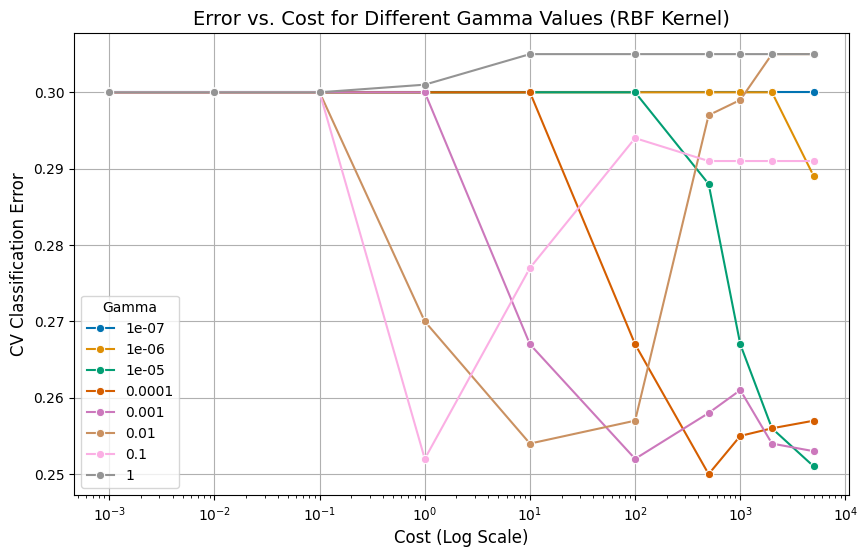

In [11]:
print("Best SVM parameters:", svm_grid.best_params_)
svm_best = svm_grid.best_estimator_
svm_cv_scores = cross_val_score(svm_best, X_std, y, cv=5)
print("SVM 5-fold CV accuracy:", np.mean(svm_cv_scores))


# Extract GridSearchCV results
svm_results = pd.DataFrame(svm_grid.cv_results_)
svm_results['mean_error'] = 1 - svm_results['mean_test_score']

# Filter results for RBF kernel
subset = svm_results[svm_results['param_kernel'] == 'rbf']
print(subset)

# Create a plot
fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(
    data=subset,
    x='param_C',
    y='mean_error',
    hue='param_gamma',
    palette='colorblind',
    marker='o',
    ax=ax
)

# Modify the axes
ax.set_xscale('log')  # Set x-axis to logarithmic scale
ax.set_title('Error vs. Cost for Different Gamma Values (RBF Kernel)', fontsize=14)
ax.set_xlabel('Cost (Log Scale)', fontsize=12)
ax.set_ylabel('CV Classification Error', fontsize=12)
ax.legend(title='Gamma', fontsize=10)
ax.grid(True)

plt.show()


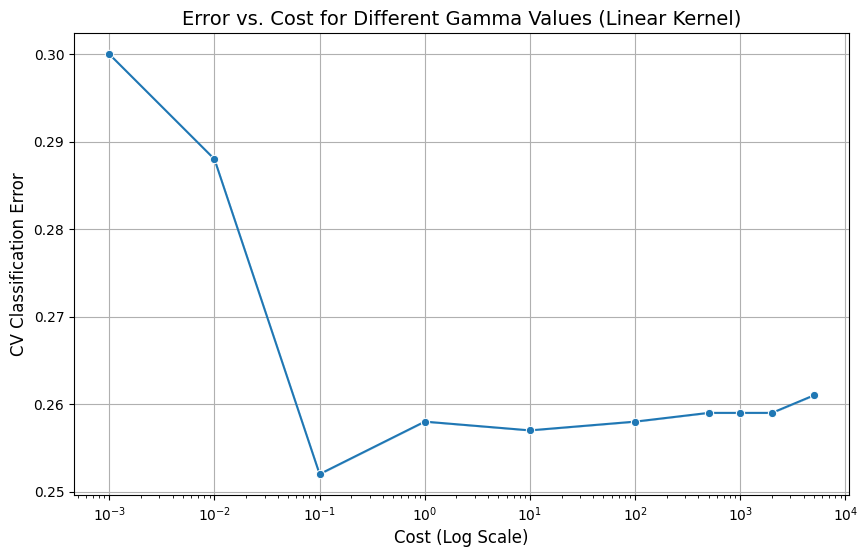

In [13]:
# Filter results for RBF kernel
subset = svm_results[svm_results['param_kernel'] == 'linear']

# Create a plot
fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(
    data=subset,
    x='param_C',
    y='mean_error',
    marker='o',
    ax=ax
)

# Modify the axes
ax.set_xscale('log')  # Set x-axis to logarithmic scale
ax.set_title('Error vs. Cost for Different Gamma Values (Linear Kernel)', fontsize=14)
ax.set_xlabel('Cost (Log Scale)', fontsize=12)
ax.set_ylabel('CV Classification Error', fontsize=12)
ax.grid(True)

plt.show()

5-fold Cross-Validation Accuracy Score: 0.7060000000000001
SVM Classification Report:
               precision    recall  f1-score   support

       False       0.72      0.98      0.83       700
        True       0.69      0.10      0.18       300

    accuracy                           0.72      1000
   macro avg       0.70      0.54      0.50      1000
weighted avg       0.71      0.72      0.63      1000



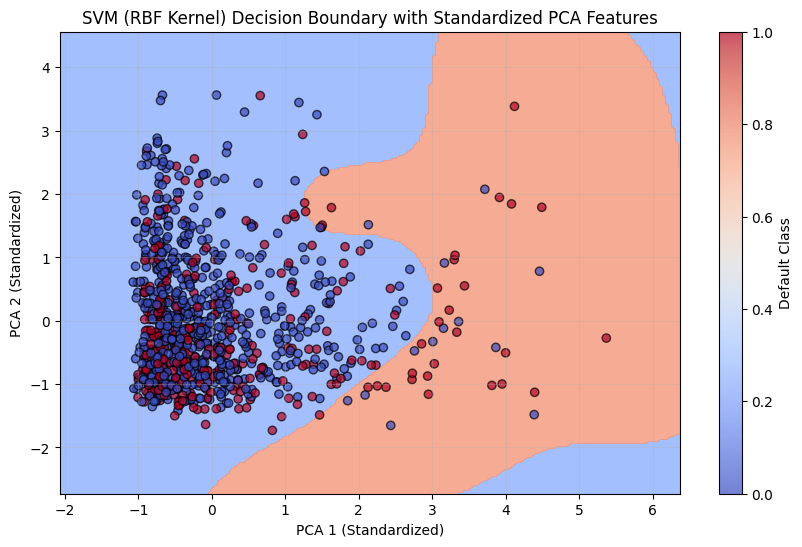

In [7]:

# Standardize the PCA components (as a separate step)
X_pca_standardized = StandardScaler().fit_transform(X_pca)

# Train an SVM classifier with an RBF kernel
svm = SVC(kernel='rbf', random_state=42, gamma='auto')
svm.fit(X_pca_standardized, y)

svm_pred = svm.predict(X_pca_standardized)
# Perform 5-fold cross-validation to calculate accuracy
cv_scores = cross_val_score(svm, X_pca_standardized, y, cv=5, scoring='accuracy')

# Print the cross-validation accuracy scores
print(f'5-fold Cross-Validation Accuracy Score: {np.mean(cv_scores)}')
print("SVM Classification Report:\n", classification_report(y, svm_pred))

# Create a finer mesh grid for plotting decision boundaries
x_min, x_max = X_pca_standardized[:, 0].min() - 1, X_pca_standardized[:, 0].max() + 1
y_min, y_max = X_pca_standardized[:, 1].min() - 1, X_pca_standardized[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

# Predict over the grid
Z = svm.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot decision boundary
plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z, alpha=0.8, cmap='coolwarm')
plt.scatter(X_pca_standardized[:, 0], X_pca_standardized[:, 1], c=y, edgecolors='k', cmap='coolwarm', alpha=0.7)
plt.title('SVM (RBF Kernel) Decision Boundary with Standardized PCA Features')
plt.xlabel('PCA 1 (Standardized)')
plt.ylabel('PCA 2 (Standardized)')
plt.grid(alpha=0.3)
plt.colorbar(label="Default Class")
plt.show()

Use XGBoost to predict default in borrowers.

In [14]:
# --- XGBoost with GridSearch and Cross-Validation ---
print("\nTuning XGBoost...")
xgb_params = {
    'n_estimators': [50, 100, 200, 300, 400],
    'max_depth': [1, 3, 5, 7, 9, 11],
    'learning_rate': [0.001, 0.01, 0.1, 0.2],
    'subsample': [0.4, 0.6, 0.8, 1.0],
    'subsample_bytree': [0.4, 0.6, 0.8, 1.0],
    'subsample_bynode': [0.4, 0.6, 0.8, 1.0]
}

xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
xgb_grid = GridSearchCV(xgb, xgb_params, cv=5, scoring='accuracy', n_jobs=-1)
xgb_grid.fit(X_std, y)



Tuning XGBoost...


c:\Python\Python3\Lib\site-packages\xgboost\core.py:158: UserWarning: [13:19:31] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0c55ff5f71b100e98-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "subsample_bynode", "subsample_bytree", "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


GridSearchCV(cv=5,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=False,
                                     eval_metric='logloss', feature_types=None,
                                     gamma=None, grow_policy=None,
                                     importance_type=None,
                                     interaction_constraints=None,
                                     learning_rate=...
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=None, num_parallel_tree=None,
                                     random_state=42, ...),
             n_jobs=-1,
             param_grid={'learning_rate': [0.001, 0.01, 0.1, 0.2],
                         'max_depth': [1, 3, 5, 7, 9, 11],
                         'n_estimators': [50, 100, 200, 300, 400],
                         'subsample': [0.4, 0.6, 0.8, 1.0],
                         'subsample_bynode': [0.4, 0.6, 0.8, 1.0],
                         'subsample_bytree': [0.4, 0.6, 0.8, 1.0]},
             scoring='accuracy')

Best XGBoost parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 50, 'subsample': 0.8, 'subsample_bynode': 0.4, 'subsample_bytree': 0.4}


c:\Python\Python3\Lib\site-packages\xgboost\core.py:158: UserWarning: [13:25:29] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0c55ff5f71b100e98-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "subsample_bynode", "subsample_bytree", "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
c:\Python\Python3\Lib\site-packages\xgboost\core.py:158: UserWarning: [13:25:29] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0c55ff5f71b100e98-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "subsample_bynode", "subsample_bytree", "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
c:\Python\Python3\Lib\site-packages\xgboost\core.py:158: UserWarning: [13:25:29] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0c55ff5f71b100e98-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "subsample_bynode", "subsample_bytree", "use_label_encod

XGBoost 5-fold CV accuracy: 0.7649999999999999
XGBoost Classification Report:
               precision    recall  f1-score   support

       False       0.83      0.94      0.88       700
        True       0.81      0.56      0.66       300

    accuracy                           0.83      1000
   macro avg       0.82      0.75      0.77      1000
weighted avg       0.82      0.83      0.82      1000



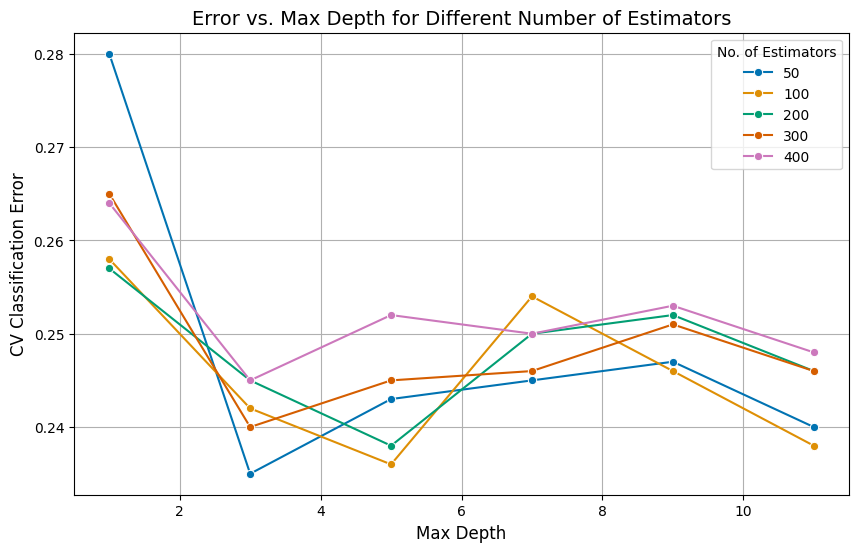

In [19]:
print("Best XGBoost parameters:", xgb_grid.best_params_)
xgb_best = xgb_grid.best_estimator_
xgb_cv_scores = cross_val_score(xgb_best, X_std, y, cv=5)
print("XGBoost 5-fold CV accuracy:", np.mean(xgb_cv_scores))

# Test XGBoost on the dataset
xgb_pred = xgb_best.predict(X_std)
print("XGBoost Classification Report:\n", classification_report(y, xgb_pred))

# Extract GridSearchCV results
xgb_results = pd.DataFrame(xgb_grid.cv_results_)
xgb_results['mean_error'] = 1 - xgb_results['mean_test_score']

# Filter results for learning_rate = 0.01
filtered_results = xgb_results[(xgb_results['param_learning_rate'] == 0.1) & (xgb_results['param_subsample']==0.8) & (xgb_results['param_subsample_bynode']==0.4) & (xgb_results['param_subsample_bytree']==0.4)]

# Create a plot
fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(
    data=filtered_results,
    x='param_max_depth',
    y='mean_error',
    hue='param_n_estimators',
    palette='colorblind',
    marker='o',
    ax=ax
)

# Customize the plot
ax.set_title('Error vs. Max Depth for Different Number of Estimators', fontsize=14)
ax.set_xlabel('Max Depth', fontsize=12)
ax.set_ylabel('CV Classification Error', fontsize=12)
ax.legend(title='No. of Estimators', fontsize=10)
ax.grid(True)

plt.show()


Use Neural Network with two hidden layers to predict default in borrowers.

In [4]:
# Define the Neural Network
class DefaultPredictorNN(nn.Module):
    def __init__(self, input_dim, hidden_dim, dropout_rate=0.5):
        super(DefaultPredictorNN, self).__init__()
        self.hidden_layer1 = nn.Linear(input_dim, hidden_dim)
        self.hidden_layer2 = nn.Linear(hidden_dim, hidden_dim)
        self.output_layer = nn.Linear(hidden_dim, 1)
        self.activation = nn.ReLU()
        self.dropout = nn.Dropout(p=dropout_rate)  # Add dropout layer

    def forward(self, x):
        x = self.activation(self.hidden_layer1(x))
        x = self.dropout(x)  # Apply dropout after the first hidden layer
        x = self.activation(self.hidden_layer2(x))
        x = self.dropout(x)  # Apply dropout after the second hidden layer
        x = self.output_layer(x)
        return torch.sigmoid(x) # Output in range (0,1)

In [ ]:
class PyTorchNN(BaseEstimator, ClassifierMixin):
    def __init__(self, input_dim, hidden_dim=32, lr=0.001, epochs=20, dropout_rate=0.5):
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.lr = lr
        self.epochs = epochs
        self.dropout_rate = dropout_rate
        self.model = DefaultPredictorNN(input_dim, hidden_dim, dropout_rate)
        self.optimizer = optim.Adam(self.model.parameters(), lr=self.lr)
        self.criterion = nn.BCELoss()  # Binary Cross Entropy Loss for probabilities
        self.epoch_history = {}

    def fit(self, X, y):
        X_tensor = torch.tensor(X, dtype=torch.float32)
        y_tensor = torch.tensor(y, dtype=torch.float32)
        self.classes_ = unique_labels(y)
        
        dataset = TensorDataset(X_tensor, y_tensor)
        loader = DataLoader(dataset, batch_size=64, shuffle=True)
        
        self.model.train()
        for epoch in range(self.epochs):
            epoch_loss = 0
            for batch_X, batch_y in loader:
                self.optimizer.zero_grad()
                outputs = self.model(batch_X)
                loss = self.criterion(outputs.squeeze(), batch_y)
                loss.backward()
                self.optimizer.step()
                epoch_loss += loss.item() * len(batch_X)  # Accumulate weighted batch loss
            
            # Track accuracy after each epoch
            epoch_accuracy = self.score(X_tensor.clone().detach(), y_tensor.clone().detach())
            self.epoch_history[epoch] = epoch_accuracy
            

        return self

    def predict(self, X):
        self.model.eval()
        if not torch.is_tensor(X):
                X_tensor = torch.tensor(X, dtype=torch.float32)
        else:
            X_tensor = X
        with torch.no_grad():
            outputs = self.model(X_tensor)
            preds = (outputs.squeeze() > 0.5).float()  # Sigmoid already applied
        return preds.numpy()

    def score(self, X, y):
        preds = self.predict(X)
        return accuracy_score(y, preds)


In [9]:
# Define the hyperparameter grid
param_grid = {
    'hidden_dim': [8, 16, 32, 64],  # Number of nodes in hidden layers
    'lr': [1e-5, 1e-4, 0.001, 0.01, 0.1],  # Learning rate
    'dropout_rate': [0.0, 0.2, 0.4, 0.6, 0.8],  # Add dropout rate to the grid
    'epochs': [200]
}

# Instantiate the model
nn_model = PyTorchNN(input_dim=X_train.shape[1])

# Perform GridSearchCV
grid_search = GridSearchCV(
    estimator=nn_model,
    param_grid=param_grid,
    cv=5,  # 5-fold cross-validation
    scoring='accuracy',
    verbose=2,
    n_jobs=-1,  # Parallelize
    error_score='raise'
)

# Fit the grid search
grid_search.fit(X_std.astype('float64').values, y.astype('float64').values)

Fitting 5 folds for each of 100 candidates, totalling 500 fits


GridSearchCV(cv=5, error_score='raise', estimator=PyTorchNN(input_dim=36),
             n_jobs=-1,
             param_grid={'dropout_rate': [0.0, 0.2, 0.4, 0.6, 0.8],
                         'epochs': [200], 'hidden_dim': [8, 16, 32, 64],
                         'lr': [1e-05, 0.0001, 0.001, 0.01, 0.1]},
             scoring='accuracy', verbose=2)

In [7]:
# Get the best parameters and score
print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Accuracy:", grid_search.best_score_)

Best Parameters: {'dropout_rate': 0.0, 'epochs': 200, 'hidden_dim': 16, 'lr': 0.0001}
Best Cross-Validation Accuracy: 0.724


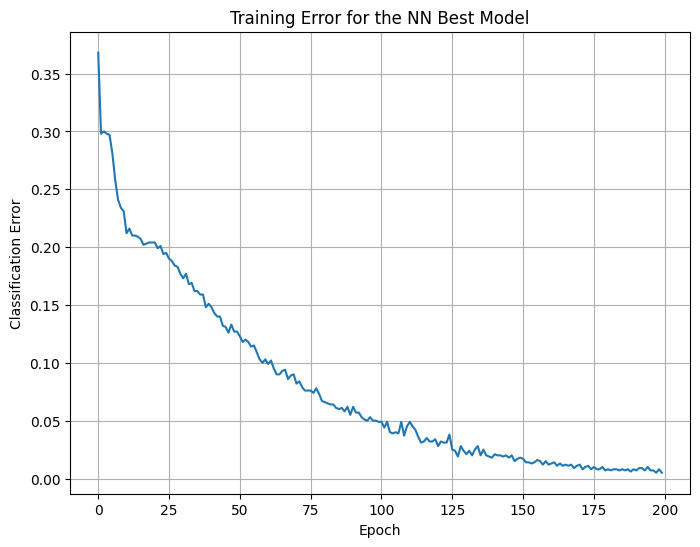

Accuracy of Best Model: 0.995


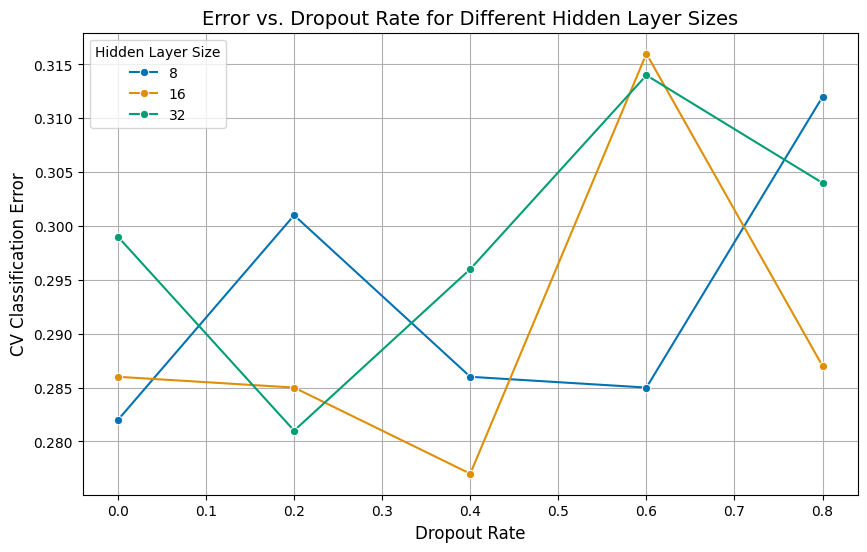

In [8]:
best_model = grid_search.best_estimator_
# Check the convergence of the best model
plt.figure(figsize=(8, 6))
epochs = list(best_model.epoch_history.keys())
losses = [1 - accuracy for accuracy in best_model.epoch_history.values()]
plt.plot(epochs, losses)
plt.title('Training Error for the NN Best Model')
plt.xlabel('Epoch')
plt.ylabel('Classification Error')
plt.grid()
plt.show()


# Use the best model on the dataset
accuracy = best_model.score(X_std.astype('float64').values, y.astype('float64').values)
print("Accuracy of Best Model:", accuracy)

# Extract GridSearchCV results
nn_results = pd.DataFrame(grid_search.cv_results_)
nn_results['mean_error'] = 1 - nn_results['mean_test_score']

# Filter results for learning_rate = 0.01
filtered_results = nn_results[(nn_results['param_lr'] == 0.001)]

# Create a plot
fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(
    data=filtered_results,
    x='param_dropout_rate',
    y='mean_error',
    hue='param_hidden_dim',
    palette='colorblind',
    marker='o',
    ax=ax
)

# Customize the plot
ax.set_title('Error vs. Dropout Rate for Different Hidden Layer Sizes', fontsize=14)
ax.set_xlabel('Dropout Rate', fontsize=12)
ax.set_ylabel('CV Classification Error', fontsize=12)
ax.legend(title='Hidden Layer Size', fontsize=10)
ax.grid(True)

plt.show()